# 🔍 Sherlock Betting Model - Auditoría Profunda de Picks y Calibración

Este notebook está diseñado para ejecutarse **localmente** en tu entorno de Sherlock. Extrae y reconstruye todos los picks históricos almacenados en `analysis_history.csv` (o directamente desde la base de datos SQLite / PostgreSQL), evalúa el resultado real de cada uno y detecta las **fallas matemáticas, sesgos de mercado y problemas de calibración**.

In [1]:
import os
import json
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Configuración gráfica
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.precision', 3)
print(" Librerías cargadas correctamente.")

 Librerías cargadas correctamente.


## 1. Carga de Datos Históricos
Cargamos el archivo `analysis_history.csv` o conectamos a la BD.

In [3]:
import sqlite3
from pathlib import Path

# Probamos varias rutas candidatas porque el cwd depende de donde vive el
# notebook al abrirlo en Jupyter (raiz del repo, dentro de data/, etc.).
DB_PATH_CANDIDATES = [
    "sherlock.db",                          # notebook corriendo DENTRO de data/
    os.path.join("data", "sherlock.db"),    # notebook corriendo desde la raiz del repo
    os.path.join("..", "data", "sherlock.db"),
    os.path.join("..", "sherlock.db"),
]
CSV_PATH_CANDIDATES = ["analysis_history.csv", os.path.join("data", "analysis_history.csv")]
TABLE_CANDIDATES = ("analysis_history", "analysishistory", "AnalysisHistory")


def _first_existing(paths):
    for p in paths:
        if os.path.exists(p):
            return os.path.abspath(p)
    return None


def _pick_table_name(conn: sqlite3.Connection) -> str:
    tables = pd.read_sql(
        "SELECT name FROM sqlite_master WHERE type='table'", conn
    )["name"].tolist()
    for cand in TABLE_CANDIDATES:
        if cand in tables:
            return cand
    lower_map = {t.lower(): t for t in tables}
    for cand in TABLE_CANDIDATES:
        if cand.lower() in lower_map:
            return lower_map[cand.lower()]
    raise RuntimeError(
        f"No se encontro una tabla de historial en la BD. Tablas disponibles: {tables}"
    )


def load_df_raw() -> pd.DataFrame:
    db_path = _first_existing(DB_PATH_CANDIDATES)
    if db_path:
        print(f"🔌 Conectando directamente a {db_path} ...")
        conn = sqlite3.connect(db_path)
        try:
            table_name = _pick_table_name(conn)
            df = pd.read_sql(
                f"SELECT * FROM {table_name} "
                f"WHERE picks_calculados IS NOT NULL AND TRIM(picks_calculados) != ''",
                conn
            )
            ## Filtrar solo registros con picks_calculados con is_value == True
            df = df[df['picks_calculados'].str.contains('"is_value": true', case=False, na=False)]
            print(f"✅ Cargados {len(df)} registros desde {db_path} (tabla '{table_name}').")
            return df
        finally:
            conn.close()


    csv_path = _first_existing(CSV_PATH_CANDIDATES)
    if csv_path:
        print(f"⚠️ sherlock.db no encontrado en {DB_PATH_CANDIDATES}. Cargando {csv_path} ...")
        df = pd.read_csv(csv_path, low_memory=False)
        print(f"Total de partidos en historial: {len(df)}")
        return df


    print("⚠️ Ni sherlock.db ni CSV encontrados en las rutas candidatas. Intentando SQLAlchemy...")
    try:
        import sys
        repo_root_candidates = [os.getcwd(), os.path.join(os.getcwd(), ".."), os.path.join(os.getcwd(), "..", "..")]
        for rc in repo_root_candidates:
            if os.path.isdir(os.path.join(rc, "src")):
                sys.path.insert(0, os.path.abspath(rc))
                break
        from src.core.database import engine
        df = pd.read_sql(
            "SELECT * FROM analysis_history "
            "WHERE picks_calculados IS NOT NULL AND TRIM(picks_calculados) != ''",
            con=engine
        )
        print(f"Cargados {len(df)} registros via SQLAlchemy.")
        return df
    except Exception as e:
        raise FileNotFoundError(
            f"No se pudo cargar datos ni desde sherlock.db (probado: {DB_PATH_CANDIDATES}), "
            f"ni CSV (probado: {CSV_PATH_CANDIDATES}), ni SQLAlchemy: {e}"
        )

df_raw = load_df_raw()
# Imprimir has_odds, tittle, match_date de los 5 registros aleatorios
df_raw.head(5)

🔌 Conectando directamente a c:\Users\cardo\01_Desarrollo\Proyectos_Personales\Sherlock\data\sherlock.db ...
✅ Cargados 491 registros desde c:\Users\cardo\01_Desarrollo\Proyectos_Personales\Sherlock\data\sherlock.db (tabla 'analysis_history').


,id,sport,date,match_title,payload,match_date,picks_calculados,user_context,llm_response,llm_timestamp,needs_reanalysis,final_score_home,final_score_away,final_corners_home,final_corners_away,final_yellow_cards_home,final_yellow_cards_away,final_red_cards_home,final_red_cards_away,final_shots_home,final_shots_away,final_shots_on_target_home,final_shots_on_target_away,accuracy_percentage,compare_response_snapshot,final_fouls_home,final_fouls_away,final_offsides_home,final_offsides_away,count_in_profitability,has_real_stats,picks_hits_summary,expected_goals_home,expected_goals_away,ball_possession_home,ball_possession_away,aerial_duels_percentage_home,aerial_duels_percentage_away,ground_duels_percentage_home,ground_duels_percentage_away,dribbles_percentage_home,dribbles_percentage_away,duel_won_percent_home,duel_won_percent_away,won_tackle_percent_home,won_tackle_percent_away,goals_prevented_home,goals_prevented_away,accurate_cross_home,accurate_cross_away,accurate_long_balls_home,accurate_long_balls_away,accurate_passes_home,accurate_passes_away,accurate_through_ball_home,accurate_through_ball_away,ball_recovery_home,ball_recovery_away,big_chance_created_home,big_chance_created_away,big_chance_missed_home,big_chance_missed_away,big_chance_scored_home,big_chance_scored_away,blocked_scoring_attempt_home,blocked_scoring_attempt_away,corner_kicks_home,corner_kicks_away,dispossessed_home,dispossessed_away,dive_saves_home,dive_saves_away,final_third_entries_home,final_third_entries_away,final_third_phase_statistic_home,final_third_phase_statistic_away,fouled_final_third_home,fouled_final_third_away,fouls_home,fouls_away,free_kicks_home,free_kicks_away,goal_kicks_home,goal_kicks_away,goalkeeper_saves_home,goalkeeper_saves_away,high_claims_home,high_claims_away,hit_woodwork_home,hit_woodwork_away,interception_won_home,interception_won_away,offsides_home,offsides_away,passes_home,passes_away,punches_home,punches_away,shots_off_goal_home,shots_off_goal_away,shots_on_goal_home,shots_on_goal_away,throw_ins_home,throw_ins_away,total_clearance_home,total_clearance_away,total_shots_inside_box_home,total_shots_inside_box_away,total_shots_on_goal_home,total_shots_on_goal_away,total_shots_outside_box_home,total_shots_outside_box_away,total_tackle_home,total_tackle_away,touches_in_opp_box_home,touches_in_opp_box_away,yellow_cards_home,yellow_cards_away,calibration_parameters,pre_match_stats,recent_form_stats,historical_pick_rates,has_odds,needs_recalc,last_recalculated_at,competition,bookmaker,stake_units
0,83d74e02-3bc1-408c-8199-cb909c302398,FOOTBALL,2026-04-03 21:03:50.511743,Fortaleza vs Inter de Bogotá,"{""home"": {""name"": ""Fortaleza"", ""matches_home"":...",2026-04-03 21:03:50.511743,"[{""selection"": ""Local"", ""odds"": 2.45, ""model_p...",,,2026-08-30 23:49:12.374542,0,1.0,1.0,2.0,3.0,0.0,0.0,0.0,0.0,10.0,17.0,3.0,7.0,100.0,"{""sport"": ""football"", ""home_name"": ""Fortaleza""...",8.0,8.0,1.0,1.0,1,1,None,0.210,0.730,50.5,49.5,7.0,8.0,13.0,15.5,0.5,4.5,46.0,54.0,7.0,5.5,None,None,1.0,5.0,33.0,38.0,303.0,287.0,NaN,NaN,40.0,32.0,0.0,1.0,NaN,NaN,0.0,1.0,1.0,3.0,2.0,3.0,6.0,7.0,None,None,63.0,67.0,NaN,NaN,3.0,1.0,8.0,8.0,8.0,8.0,9.0,9.0,6.0,2.0,None,None,0.0,0.0,6.0,11.0,1.0,1.0,370.0,355.0,None,None,6.0,7.0,3.0,7.0,24.0,24.0,25.0,14.0,6.0,10.0,10.0,17.0,4.0,7.0,17.0,14.0,NaN,NaN,NaN,NaN,None,"{""league_averages"": {""home_goals"": 1.341191066...","{""home"": {""last_5"": {""sample_size"": 5, ""goals_...","{""home_over25_home"": {""sample_size"": 25, ""hits...",0,1,None,Primera A,None,5.0
2,b5cc5541-2b47-4e0d-8f25-334d853e640c,FOOTBALL,2026-04-04 05:45:33.331646,Stuttgart vs Dortmund,"{""home"": {""name"": ""Stuttgart"", ""matches_home"":...",2026-04-04 05:45:33.331646,"[{""selection"": ""Local"", ""odds"": 2.27, ""model_p...",None,None,2026-05-02 05:59:08.213999,0,0.0,2.0,5.0,2.0,2.0,4.0,0.0,0.0,13.0,5.0,3.0,3.0,100.0,"{""sport"": ""football"", ""home_name"": ""Stuttgart""...",10.0,12.0,3.0,0.0,0,1,None,0.380,0.305,67.0,33.0,13.5,7.5,1

## 2. Funciones de Clasificación y Liquidación de Mercados
Definimos la lógica de normalización de familias de mercado, extracción de líneas y liquidación de apuestas (incluyendo medias líneas asiáticas).

In [4]:
def classify_market_family(selection_str):
    if not isinstance(selection_str, str):
        return 'otro'
    s = selection_str.strip().lower()
    if any(k in s for k in ['btts', 'ambos marcan', 'both teams to score']):
        return 'btts'
    if any(k in s for k in ['corner', 'córner', 'corners', 'córners']):
        return 'corners'
    if any(k in s for k in ['tarjeta', 'tarjetas', 'cards', 'yellow cards', 'amarillas']):
        return 'cards'
    if any(k in s for k in ['foul', 'fouls', 'faltas']):
        return 'fouls'
    if any(k in s for k in ['pta', 'a puerta', 'target', 'shotstarget', 'shottarget']):
        return 'shotstarget'
    if any(k in s for k in ['shot', 'shots', 'tiros', 'remates']):
        return 'shots'
    if any(k in s for k in ['double chance', 'doble oportunidad', '1x', 'x2', '12']):
        return 'doublechance'
    if s in ['local', 'visitante', 'empate', 'home', 'away', 'draw'] or any(k in s for k in ['moneyline', 'ml', '1x2', 'ganador']):
        return 'result'
    if any(k in s for k in ['gol', 'goles', 'goal', 'goals']):
        return 'goals'
    return 'otro'

def extract_line_and_side(selection_str, explicit_line=None):
    s = str(selection_str).lower()
    side = 'over' if 'over' in s or 'más de' in s or 'mas de' in s else ('under' if 'under' in s or 'menos de' in s else None)
    line = explicit_line
    if line is None or pd.isna(line):
        m = re.search(r'(\d+(?:\.\d+)?)', s)
        if m:
            try:
                line = float(m.group(1))
            except:
                line = None
    return line, side

def evaluate_pick_outcome(selection, explicit_line, res_dict):
    """
    Liquida un pick contra el diccionario de resultados finales.
    Retorna True (Acierto), False (Fallo), 'push' (Empate/Nula), 'half_win', 'half_loss' o None.
    """
    s = str(selection).strip().lower()
    fam = classify_market_family(s)
    
    hscore = res_dict.get('finalscorehome')
    ascore = res_dict.get('finalscoreaway')
    
    # 1. 1X2
    if fam == 'result':
        if hscore is None or ascore is None: return None
        if s in ['local', 'home'] or '1x2 local' in s:
            return hscore > ascore
        if s in ['visitante', 'away'] or '1x2 visitante' in s:
            return ascore > hscore
        if s in ['empate', 'draw'] or '1x2 empate' in s:
            return hscore == ascore
            
    # 2. Doble Oportunidad
    if fam == 'doublechance':
        if hscore is None or ascore is None: return None
        if '1x' in s: return hscore >= ascore
        if 'x2' in s: return ascore >= hscore
        if '12' in s: return hscore != ascore
        
    # 3. BTTS
    if fam == 'btts':
        if hscore is None or ascore is None: return None
        both = (hscore > 0 and ascore > 0)
        if 'no' in s:
            return not both
        return both
        
    # 4. Mercados de Líneas Over / Under
    line, side = extract_line_and_side(s, explicit_line)
    if line is None or side is None: return None
    
    actual_stat = None
    if fam == 'goals':
        if hscore is not None and ascore is not None:
            actual_stat = hscore + ascore
    elif fam == 'corners':
        hc = res_dict.get('finalcornershome')
        ac = res_dict.get('finalcornersaway')
        if hc is not None and ac is not None:
            actual_stat = hc + ac
    elif fam == 'cards':
        hy = res_dict.get('finalyellowcardshome') or 0
        ay = res_dict.get('finalyellowcardsaway') or 0
        hr = res_dict.get('finalredcardshome') or 0
        ar = res_dict.get('finalredcardsaway') or 0
        if res_dict.get('finalyellowcardshome') is not None:
            actual_stat = hy + ay + (hr + ar) * 2
    elif fam == 'shots':
        hs = res_dict.get('finalshotshome')
        as_ = res_dict.get('finalshotsaway')
        if hs is not None and as_ is not None:
            actual_stat = hs + as_
    elif fam == 'shotstarget':
        hst = res_dict.get('finalshotsontargethome')
        ast = res_dict.get('finalshotsontargetaway')
        if hst is not None and ast is not None:
            actual_stat = hst + ast
    elif fam == 'fouls':
        hf = res_dict.get('finalfoulshome')
        af = res_dict.get('finalfoulsaway')
        if hf is not None and af is not None:
            actual_stat = hf + af
            
    if actual_stat is None:
        return None
        
    # Manejo de línea regular y asiática
    diff = actual_stat - line
    if side == 'over':
        if diff > 0.25: return True
        if diff == 0.25: return 'half_win'
        if diff == 0: return 'push'
        if diff == -0.25: return 'half_loss'
        return False
    elif side == 'under':
        if diff < -0.25: return True
        if diff == -0.25: return 'half_win'
        if diff == 0: return 'push'
        if diff == 0.25: return 'half_loss'
        return False
        
    return None

In [5]:
def classify_market_side(selection_str, family=None):
    """
    Devuelve el 'lado' de la selección (over/under, yes/no, home/away/draw,
    1x/x2/12) usando límites de palabra (\b) en vez de subcadenas sueltas.
    Evita falsos positivos como 'no' apareciendo dentro de nombres de equipo
    u otras palabras (ej. "Torino", "Bolonia" contienen "no" como substring).
    """
    if not isinstance(selection_str, str):
        return None
    s = selection_str.strip().lower()

    patterns = [
        (r'\b(over|más\s+de|mas\s+de)\b', 'over'),
        (r'\b(under|menos\s+de)\b', 'under'),
        (r'\b(sí|si|yes)\b', 'yes'),
        (r'\bno\b', 'no'),
        (r'\b(local|home)\b', 'home'),
        (r'\b(visitante|away)\b', 'away'),
        (r'\b(empate|draw)\b', 'draw'),
        (r'\b1x\b', 'home_draw'),
        (r'\bx2\b', 'draw_away'),
        (r'\b12\b', 'home_away'),
    ]
    for pattern, side in patterns:
        if re.search(pattern, s):
            return side
    return None


def market_group_key(selection_str):
    """
    Clave de agrupación fina para correlación: familia + lado cuando el lado
    es relevante. Si no se detecta lado, usa solo la familia (no se pierden
    datos de mercados sin lado claro).
    """
    fam = classify_market_family(selection_str)
    side = classify_market_side(selection_str, family=fam)
    return f"{fam}_{side}" if side else fam

## 3. Extracción y Desempaquetado de Picks
Iteramos sobre todos los partidos históricos y expandimos cada pick generado por el modelo.

In [6]:
picks_list = []

def get_field(r, *aliases, default=None):
    for a in aliases:
        if a in r and pd.notna(r[a]):
            return r[a]
    return default

def get_pick_val(p, *keys, default=None):
    """Busca un valor en el diccionario del pick probando variantes camelCase y snake_case."""
    for k in keys:
        if k in p and p[k] is not None:
            return p[k]
    return default

for idx, row in df_raw.iterrows():
    match_id = get_field(row, 'id', 'match_id', default=idx)
    match_title = get_field(row, 'matchtitle', 'match_title', default='Desconocido')
    match_date = get_field(row, 'matchdate', 'match_date', 'date', default=None)
    
    # 1. Parsear liga
    league_name = 'Desconocida'
    payload_raw = get_field(row, 'payload')
    if isinstance(payload_raw, str) and payload_raw.strip():
        try:
            pdata = json.loads(payload_raw)
            league_name = pdata.get('competition') or pdata.get('tournament', {}).get('name') or 'Desconocida'
        except Exception:
            pass
    elif isinstance(payload_raw, dict):
        league_name = payload_raw.get('competition') or payload_raw.get('tournament', {}).get('name') or 'Desconocida'
            
    # 2. Resultados finales del partido
    res_dict = {
        'finalscorehome': get_field(row, 'finalscorehome', 'final_score_home'),
        'finalscoreaway': get_field(row, 'finalscoreaway', 'final_score_away'),
        'finalcornershome': get_field(row, 'finalcornershome', 'final_corners_home'),
        'finalcornersaway': get_field(row, 'finalcornersaway', 'final_corners_away'),
        'finalyellowcardshome': get_field(row, 'finalyellowcardshome', 'final_yellow_cards_home'),
        'finalyellowcardsaway': get_field(row, 'finalyellowcardsaway', 'final_yellow_cards_away'),
        'finalredcardshome': get_field(row, 'finalredcardshome', 'final_red_cards_home'),
        'finalredcardsaway': get_field(row, 'finalredcardsaway', 'final_red_cards_away'),
        'finalshotshome': get_field(row, 'finalshotshome', 'final_shots_home'),
        'finalshotsaway': get_field(row, 'finalshotsaway', 'final_shots_away'),
        'finalshotsontargethome': get_field(row, 'finalshotsontargethome', 'final_shots_on_target_home'),
        'finalshotsontargetaway': get_field(row, 'finalshotsontargetaway', 'final_shots_on_target_away'),
        'finalfoulshome': get_field(row, 'finalfoulshome', 'final_fouls_home'),
        'finalfoulsaway': get_field(row, 'finalfoulsaway', 'final_fouls_away'),
    }
    
    # 3. Extraer picks de pickscalculados o snapshot
    picks_raw = get_field(row, 'pickscalculados', 'picks_calculados')
    picks_data = None
    
    if isinstance(picks_raw, str) and picks_raw.strip():
        try:
            picks_data = json.loads(picks_raw)
        except Exception:
            pass
    elif isinstance(picks_raw, list):
        picks_data = picks_raw
        
    if not isinstance(picks_data, list) or len(picks_data) == 0:
        snap_raw = get_field(row, 'compareresponsesnapshot', 'compare_response_snapshot')
        if isinstance(snap_raw, str) and snap_raw.strip():
            try:
                snap_dict = json.loads(snap_raw)
                if isinstance(snap_dict, dict) and 'values' in snap_dict:
                    picks_data = snap_dict['values']
            except Exception:
                pass
        elif isinstance(snap_raw, dict) and 'values' in snap_raw:
            picks_data = snap_raw['values']

    if not isinstance(picks_data, list) or len(picks_data) == 0:
        continue
        
    for p in picks_data:
        if not isinstance(p, dict):
            continue
            
        sel = get_pick_val(p, 'selection', 'Selection', 'sel')
        market_group = market_group_key(sel)
        odds = get_pick_val(p, 'odds', 'Odds')
        line = get_pick_val(p, 'line', 'Line')
        outcome = evaluate_pick_outcome(sel, line, res_dict)
        
        profit_1u = 0.0
        is_hit = False
        if outcome is True:
            profit_1u = (odds - 1.0) if (odds and odds > 1.0) else 0.0
            is_hit = True
        elif outcome is False:
            profit_1u = -1.0
        elif outcome == 'half_win':
            profit_1u = ((odds - 1.0) / 2.0) if (odds and odds > 1.0) else 0.0
            is_hit = True
        elif outcome == 'half_loss':
            profit_1u = -0.5
            
        # Extraer probabilidades con soporte para camelCase y snake_case
        m_prob = get_pick_val(p, 'modelProb', 'model_prob', 'modelprob', 'prob', 'modelProbability')
        c_prob = get_pick_val(p, 'calibratedProb', 'calibrated_prob', 'calibratedprob')
        imp_prob = get_pick_val(p, 'impliedProb', 'implied_prob', 'impliedprob')
        if imp_prob is None and odds and odds > 1.0:
            imp_prob = 1.0 / odds * 100.0
            
        picks_list.append({
            'match_id': match_id,
            'match_title': match_title,
            'match_date': match_date,
            'league': league_name,
            'selection': sel,
            'market_family': classify_market_family(sel),
            'side': classify_market_side(sel, family=classify_market_family(sel)),
            'market_group': market_group,
            'line': line,
            'odds': odds,
            'model_prob': m_prob,
            'calibrated_prob': c_prob,
            'implied_prob': imp_prob,
            'edge_ev': get_pick_val(p, 'edgeEv', 'edge_ev', 'edgeev', 'ev'),
            'edge': get_pick_val(p, 'edge', 'Edge'),
            'stake_units': get_pick_val(p, 'stakeUnits', 'stake_units', 'stakeunits', default=1.0),
            'kelly_fraction': get_pick_val(p, 'kellyFraction', 'kelly_fraction', 'kellyfraction'),
            'is_value': get_pick_val(p, 'isValue', 'is_value', 'isvalue', default=False),
            'is_publishable': get_pick_val(p, 'isPublishable', 'is_publishable', 'ispublishable', default=False),
            'is_underdog': get_pick_val(p, 'isUnderdog', 'is_underdog', 'isunderdog', default=False),
            'is_blacklisted': get_pick_val(p, 'isBlacklisted', 'is_blacklisted', 'isblacklisted', default=False),
            'is_rule_blocked': get_pick_val(p, 'isRuleBlocked', 'is_rule_blocked', 'isruleblocked', default=False),
            'outcome': outcome,
            'is_hit': is_hit,
            'profit_1u': profit_1u,
            'count_in_profitability': get_field(row, 'countinprofitability', 'count_in_profitability', default=True)
        })

df_picks = pd.DataFrame(picks_list)
df_eval = df_picks[df_picks['outcome'].notna()].copy()

print(f"✅ Total de picks deserializados: {len(df_picks)}")
print(f"📊 Picks evaluados con resultado final: {len(df_eval)}")
print(f"🎯 Picks con 'model_prob' disponible: {df_eval['model_prob'].notna().sum()}")
print(f"🎯 Picks con 'calibrated_prob' disponible: {df_eval['calibrated_prob'].notna().sum()}")

✅ Total de picks deserializados: 8178
📊 Picks evaluados con resultado final: 8118
🎯 Picks con 'model_prob' disponible: 8118
🎯 Picks con 'calibrated_prob' disponible: 7934


### 4bis.1 Matriz de correlación empírica por familia de mercado

Para cada partido (`match_id`), promediamos el resultado (`is_hit`) de los picks de cada familia
que aparecieron en ese partido. Esto da, por partido, una fila con el hit-rate por familia
(0, 0.5, 1 o NaN si esa familia no tuvo pick en ese partido). La correlación de Pearson sobre
esas columnas binarias/proporcionales es el coeficiente **phi**: mide si dos familias tienden a
acertar/fallar juntas en los mismos partidos, más allá de lo que digan sus nombres.

In [9]:
MIN_CO_OCCURRENCE = 30  # pares con menos partidos en común que esto no son confiables

# Agrupamos por familia + lado (over/under, yes/no, home/away/draw) en vez de
# solo por familia. Mezclar Over y Under (o Sí/No) en la misma columna
# promediaba resultados de apuestas opuestas y colapsaba la varianza real,
# lo que producía correlaciones en NaN (std=0) para btts/doublechance/result.
if "market_group" not in df_eval.columns:
    df_eval["market_group"] = df_eval["selection"].apply(market_group_key)

pivot_hits = (
    df_eval
    .pivot_table(index="match_id", columns="market_group", values="is_hit", aggfunc="mean")
)

# Diagnóstico de varianza cero ANTES de calcular la correlación: si vuelve a
# salir un NaN, aquí ves exactamente qué grupo lo causó y por qué.
group_std = pivot_hits.std(skipna=True)
zero_variance_groups = group_std[group_std.fillna(0) == 0].index.tolist()
if zero_variance_groups:
    print(f"⚠️ Grupos con varianza cero (is_hit constante en todos los partidos): {zero_variance_groups}")
    print("   Investiga evaluate_pick_outcome() para esos grupos específicos —")
    print("   con la nueva clasificación por lado, esto ya no debería incluir btts/result completos.")

corr_matrix = pivot_hits.corr(method="pearson")

valid_mask = pivot_hits.notna().astype(int)
co_occurrence = valid_mask.T.dot(valid_mask)

corr_matrix_reliable = corr_matrix.where(co_occurrence >= MIN_CO_OCCURRENCE)

print(f"Grupos (familia+lado) detectados: {list(pivot_hits.columns)}")
print(f"Partidos usados para la matriz: {pivot_hits.shape[0]}")
corr_matrix_reliable.round(2)

Grupos (familia+lado) detectados: ['btts_no', 'btts_yes', 'cards_over', 'cards_under', 'corners_over', 'corners_under', 'doublechance_draw_away', 'doublechance_home_away', 'doublechance_home_draw', 'goals_over', 'goals_under', 'result_away', 'result_draw', 'result_home', 'shots_over', 'shots_under', 'shotstarget_over', 'shotstarget_under']
Partidos usados para la matriz: 1798


market_group,btts_no,btts_yes,cards_over,cards_under,corners_over,corners_under,doublechance_draw_away,doublechance_home_away,doublechance_home_draw,goals_over,goals_under,result_away,result_draw,result_home,shots_over,shots_under,shotstarget_over,shotstarget_under
market_group,,,,,,,,,,,,,,,,,,
btts_no,1.00,-1.00,-0.03,0.03,0.01,0.02,-0.09,0.17,-0.06,-0.27,0.35,0.06,-0.17,0.09,-0.14,0.15,-0.26,0.27
btts_yes,-1.00,1.00,0.03,-0.03,-0.01,-0.02,0.09,-0.17,0.06,0.27,-0.35,-0.06,0.17,-0.09,0.14,-0.15,0.26,-0.27
cards_over,-0.03,0.03,1.00,-0.66,-0.01,-0.04,-0.01,-0.02,0.03,0.04,0.01,-0.03,0.02,0.01,-0.03,-0.00,0.02,-0.04
cards_under,0.03,-0.03,-0.66,1.00,0.00,-0.00,0.01,-0.00,-0.01,0.01,-0.00,0.01,0.00,-0.01,0.00,-0.03,0.02,0.07
corners_over,0.01,-0.01,-0.01,0.00,1.00,-0.31,-0.02,0.01,0.01,0.03,0.01,-0.01,-0.01,0.02,0.13,-0.16,0.05,-0.07
corners_under,0.02,-0.02,-0.04,-0.00,-0.31,1.00,-0.02,0.03,-0.01,-0.02,0.05,0.01,-0.03,0.02,-0.19,0.20,-0.08,0.06
doublechance_draw_away,-0.09,0.09,-0.01,0.01,-0.02,-0.02,1.00,-0.51,-0.58,-0.09,0.06,0.58,0.51,-1.00,-0.01,0.01,-0.03,0.07
doublechance_home_away,0.17,-0.17,-0.02,-0.00,0.01,0.03,-0.51,1.00,-0.41,0.12,-0.11,0.41,-1.00,0.51,0.04,-0.05,0.05,-0.14
doublechance_home_draw,-0.06,0.06,0.03,-0.01,0.01,-0.01,-0.58,-0.41,1.00,-0.02,0.05,-1.00,0.41,0.58,-0.03,0.04,-0.02,0.06


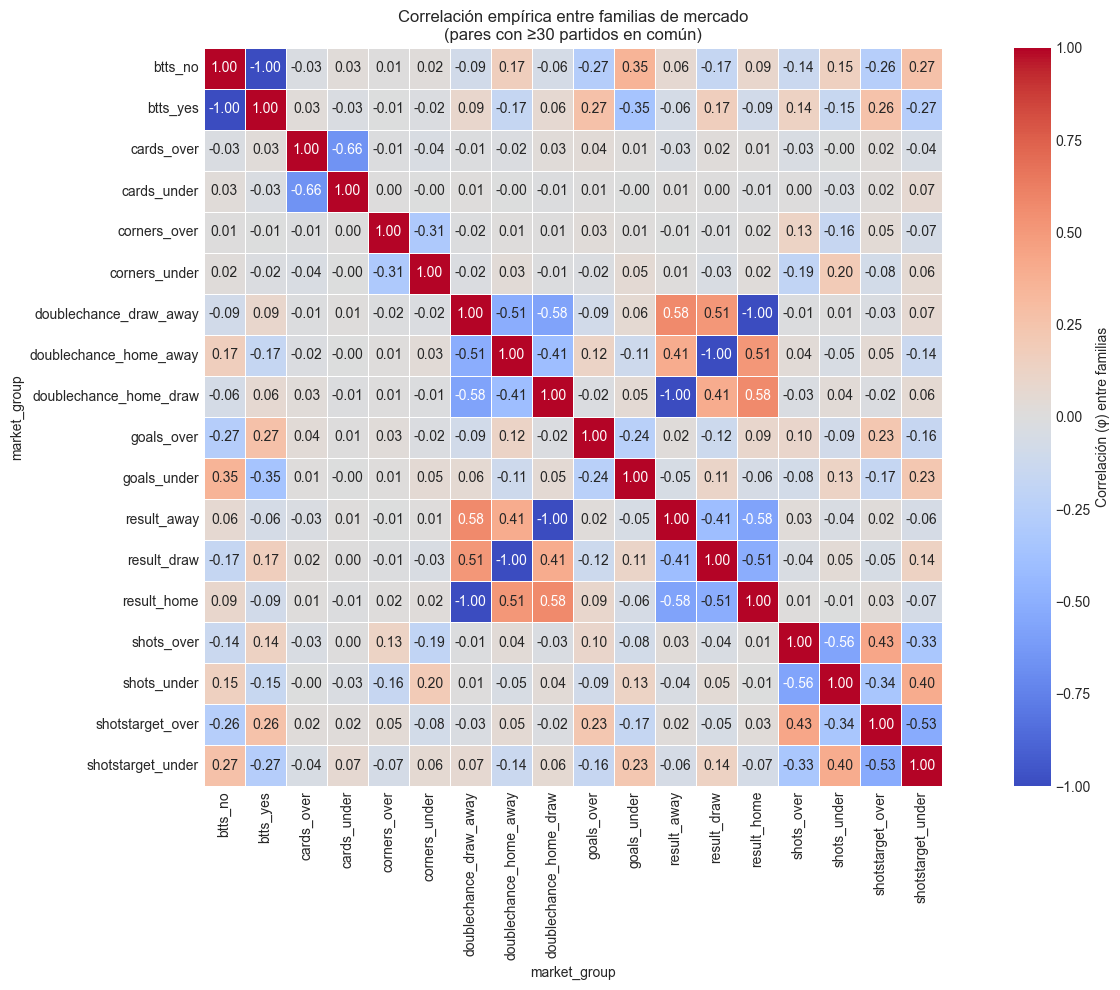

In [10]:
fig, ax = plt.subplots(figsize=(15, 10))
sns.heatmap(
    corr_matrix_reliable,
    annot=True, fmt=".2f", cmap="coolwarm", center=0,
    vmin=-1, vmax=1, square=True, linewidths=0.5,
    cbar_kws={"label": "Correlación (φ) entre familias"},
    ax=ax,
)
ax.set_title(f"Correlación empírica entre familias de mercado\n(pares con ≥{MIN_CO_OCCURRENCE} partidos en común)")
plt.tight_layout()
plt.show()

### 4bis.2 Ranking de pares correlacionados + export para producción

Sacamos el ranking de pares de familias más correlacionadas (en valor absoluto) y lo exportamos
a `data/market_correlation.json`. Ese archivo está pensado para sustituir/alimentar
`exclusive_groups` en `pick_rules_engine.py`: en vez de una lista fija de familias excluyentes,
el motor de reglas puede leer el `rho` real y decidir con un umbral (por ejemplo, penalizar o
bloquear combinaciones con `abs(rho) > 0.35` y `n >= 30`), en lugar de una heurística de texto.

In [8]:
pairs = []
fams = corr_matrix.columns.tolist()
for i, fa in enumerate(fams):
    for fb in fams[i + 1:]:
        n = int(co_occurrence.loc[fa, fb]) if fa in co_occurrence.index and fb in co_occurrence.columns else 0
        rho = corr_matrix.loc[fa, fb]
        pairs.append({"family_a": fa, "family_b": fb, "rho": None if pd.isna(rho) else round(float(rho), 4), "n_matches": n})


df_pairs = pd.DataFrame(pairs)
df_pairs_reliable = df_pairs[df_pairs["n_matches"] >= MIN_CO_OCCURRENCE].copy()
df_pairs_reliable["abs_rho"] = df_pairs_reliable["rho"].abs()
df_pairs_reliable = df_pairs_reliable.sort_values("abs_rho", ascending=False)


print("🔝 Pares de familias más correlacionados (con muestra confiable):")
display_cols = ["family_a", "family_b", "rho", "n_matches"]
print(df_pairs_reliable[display_cols].head(15).to_string(index=False))


# Export para consumo desde src/core/pick_rules_engine.py.
# Reutilizamos la misma deteccion de ruta que 1bis (DB_PATH_CANDIDATES /
# _first_existing) en vez de una ruta relativa fija: asi el JSON siempre
# queda junto a sherlock.db, sin importar el cwd desde el que se abrio
# el notebook (raiz del repo o dentro de data/).
_db_path_found = _first_existing(DB_PATH_CANDIDATES)
if _db_path_found:
    _data_dir = os.path.dirname(_db_path_found)
else:
    # Fallback si por algun motivo no se detecto sherlock.db en esta corrida:
    # usa el primer candidato de CSV, o el cwd actual como ultimo recurso.
    _csv_found = _first_existing(CSV_PATH_CANDIDATES) if "CSV_PATH_CANDIDATES" in globals() else None
    _data_dir = os.path.dirname(_csv_found) if _csv_found else os.getcwd()

os.makedirs(_data_dir, exist_ok=True)
export_path = os.path.join(_data_dir, "market_correlation.json")

export_payload = {
    "generated_at": datetime.utcnow().isoformat(),
    "min_co_occurrence": MIN_CO_OCCURRENCE,
    "pairs": df_pairs_reliable[display_cols].to_dict(orient="records"),
    "suggested_thresholds": {
        "block_above_abs_rho": 0.5,
        "penalize_above_abs_rho": 0.3,
    },
}
with open(export_path, "w", encoding="utf-8") as f:
    json.dump(export_payload, f, indent=2, ensure_ascii=False)


print(f"\n💾 Matriz de correlación exportada a {export_path}")

🔝 Pares de familias más correlacionados (con muestra confiable):
              family_a               family_b    rho  n_matches
               btts_no               btts_yes -1.000       1426
doublechance_home_draw            result_away -1.000       1426
doublechance_draw_away            result_home -1.000       1426
doublechance_home_away            result_draw -1.000       1426
            cards_over            cards_under -0.644        844
            shots_over            shots_under -0.613        652
      shotstarget_over      shotstarget_under -0.594        652
doublechance_draw_away doublechance_home_draw -0.573       1426
           result_away            result_home -0.573       1426
doublechance_home_draw            result_home  0.573       1426
doublechance_draw_away            result_away  0.573       1426
           result_draw            result_home -0.514       1426
doublechance_draw_away doublechance_home_away -0.514       1426
doublechance_home_away            resul

C:\Users\cardo\AppData\Local\Temp\ipykernel_9412\3726596912.py:39: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  "generated_at": datetime.utcnow().isoformat(),


### 4bis.3 Monte Carlo con cópula gaussiana: probabilidad conjunta real de un combinado

Cuando dos picks del mismo partido son de familias correlacionadas, `P(A∩B) ≠ P(A)·P(B)`.
Aquí simulamos variables Bernoulli correlacionadas (vía cópula gaussiana, usando la matriz `rho`
medida arriba) para estimar la probabilidad conjunta REAL de que ambas partes de un combo
acierten, y la comparamos contra la probabilidad ingenua de independencia. La diferencia es
exactamente el sesgo que un modelo de "picks independientes" comete al calcular EV de un combo.

In [9]:

try:
    from scipy.stats import norm
    _HAS_SCIPY = True
except ImportError:
    _HAS_SCIPY = False

    # Aproximacion de Acklam para la inversa de la normal estandar,
    # usada solo si scipy no esta disponible en el entorno.
    def _norm_ppf(p):
        p = np.clip(np.asarray(p, dtype=float), 1e-10, 1 - 1e-10)
        a = [-3.969683028665376e+01, 2.209460984245205e+02, -2.759285104469687e+02,
             1.383577518672690e+02, -3.066479806614716e+01, 2.506628277459239e+00]
        b = [-5.447609879822406e+01, 1.615858368580409e+02, -1.556989798598866e+02,
             6.680131188771972e+01, -1.328068155288572e+01]
        c = [-7.784894002430293e-03, -3.223964580411365e-01, -2.400758277161838e+00,
             -2.549732539343734e+00, 4.374664141464968e+00, 2.938163982698783e+00]
        d = [7.784695709041462e-03, 3.224671290700398e-01, 2.445134137142996e+00,
             3.754408661907416e+00]
        plow, phigh = 0.02425, 1 - 0.02425
        out = np.empty_like(p)
        low = p < plow
        high = p > phigh
        mid = ~(low | high)
        q = np.sqrt(-2 * np.log(p[low]))
        out[low] = (((((c[0]*q+c[1])*q+c[2])*q+c[3])*q+c[4])*q+c[5]) / ((((d[0]*q+d[1])*q+d[2])*q+d[3])*q+1)
        q = np.sqrt(-2 * np.log(1 - p[high]))
        out[high] = -(((((c[0]*q+c[1])*q+c[2])*q+c[3])*q+c[4])*q+c[5]) / ((((d[0]*q+d[1])*q+d[2])*q+d[3])*q+1)
        q = p[mid] - 0.5
        r = q * q
        out[mid] = (((((a[0]*r+a[1])*r+a[2])*r+a[3])*r+a[4])*r+a[5])*q / (((((b[0]*r+b[1])*r+b[2])*r+b[3])*r+b[4])*r+1)
        return out

    class _NormFallback:
        @staticmethod
        def ppf(p):
            return _norm_ppf(np.asarray(p))
    norm = _NormFallback()


def gaussian_copula_joint_prob(marginal_probs, corr_sub, n_sims=100_000, seed=42):
    # marginal_probs: lista/array de P(hit) de cada pick (marginales Bernoulli).
    # corr_sub: submatriz de correlacion (misma dimension que marginal_probs) usada como
    #           proxy de la correlacion gaussiana latente entre los picks.
    # Devuelve (prob_copula, prob_independencia) para el mismo conjunto de picks.
    k = len(marginal_probs)
    marginal_probs = np.clip(np.asarray(marginal_probs, dtype=float), 1e-6, 1 - 1e-6)
    C = np.nan_to_num(np.array(corr_sub, dtype=float), nan=0.0)
    np.fill_diagonal(C, 1.0)
    C = (C + C.T) / 2.0  # simetrizar por seguridad numerica

    eigvals = np.linalg.eigvalsh(C)
    if eigvals.min() < 1e-6:
        C = C + np.eye(k) * (1e-6 - eigvals.min())

    rng = np.random.default_rng(seed)
    z = rng.multivariate_normal(mean=np.zeros(k), cov=C, size=n_sims)
    thresholds = norm.ppf(1 - marginal_probs)  # P(Z > umbral) = marginal_probs
    hits = z > thresholds
    joint_hit = hits.all(axis=1)

    prob_copula = float(joint_hit.mean())
    prob_independencia = float(np.prod(marginal_probs))
    return prob_copula, prob_independencia


# --- Aplicacion sobre combos reales del historial ---------------------------
# Para cada partido con >=2 picks evaluados, medimos cuanto se sobreestima el
# combo si se asume independencia, usando el hit-rate historico de cada
# familia como proxy de su probabilidad marginal.
family_hit_rate = df_eval.groupby("market_group")["is_hit"].mean().to_dict()

combo_rows = []
for match_id, group in df_eval.groupby("match_id"):
    fams_in_match = group["market_group"].dropna().unique().tolist()
    fams_in_match = [f for f in fams_in_match if f in corr_matrix.columns]
    if len(fams_in_match) < 2:
        continue

    sub_corr = corr_matrix.loc[fams_in_match, fams_in_match].fillna(0.0).values
    marg = [family_hit_rate.get(f, np.nan) for f in fams_in_match]
    if any(pd.isna(m) for m in marg):
        continue

    p_cop, p_ind = gaussian_copula_joint_prob(marg, sub_corr, n_sims=20_000)
    actual_all_hit = group.groupby("market_group")["is_hit"].mean().reindex(fams_in_match)
    actual_joint = float((actual_all_hit >= 0.5).all())

    combo_rows.append({
        "match_id": match_id,
        "families": ",".join(fams_in_match),
        "n_families": len(fams_in_match),
        "prob_independencia": round(p_ind, 4),
        "prob_copula": round(p_cop, 4),
        "sobreestimacion_pct": round(((p_ind / p_cop) - 1) * 100, 1) if p_cop > 0 else np.nan,
    })

df_combo = pd.DataFrame(combo_rows)
print(f"Combos evaluados (partidos con >=2 familias): {len(df_combo)}")
df_combo.describe(include="all").T.loc[["prob_independencia", "prob_copula", "sobreestimacion_pct"]]


Combos evaluados (partidos con >=2 familias): 1131


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
prob_independencia,1131.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.003
prob_copula,1131.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
sobreestimacion_pct,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


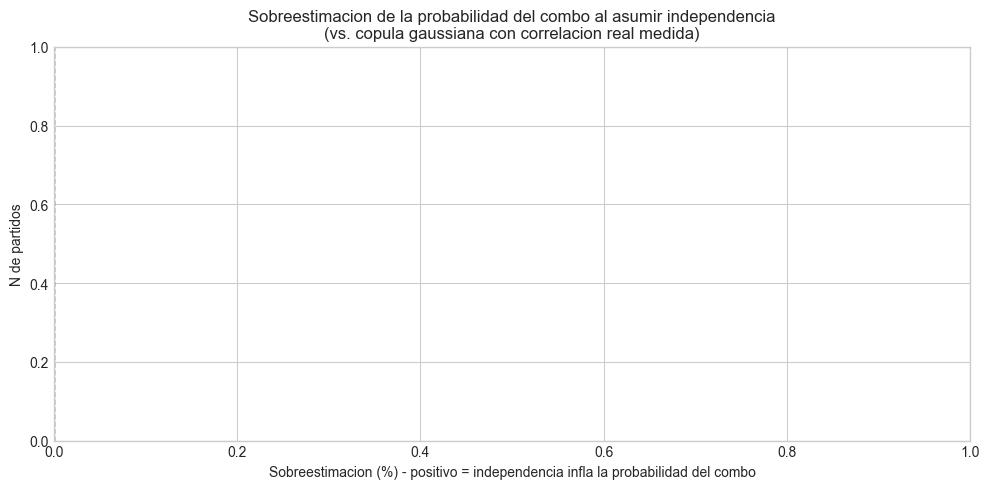

Sobreestimacion promedio al asumir independencia: nan%
Valores positivos altos -> esas combinaciones de familias son mas riesgosas de lo que el EV 'ingenuo' sugiere.


In [10]:

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df_combo["sobreestimacion_pct"].dropna(), bins=40, kde=True, ax=ax, color="crimson")
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_title("Sobreestimacion de la probabilidad del combo al asumir independencia\n(vs. copula gaussiana con correlacion real medida)")
ax.set_xlabel("Sobreestimacion (%) - positivo = independencia infla la probabilidad del combo")
ax.set_ylabel("N de partidos")
plt.tight_layout()
plt.show()

media = df_combo["sobreestimacion_pct"].mean()
print(f"Sobreestimacion promedio al asumir independencia: {media:.1f}%")
print("Valores positivos altos -> esas combinaciones de familias son mas riesgosas de lo que el EV 'ingenuo' sugiere.")


### 4bis.4 Monte Carlo de portafolio: bankroll y drawdown con vs. sin ajuste por correlación

Última pieza: en lugar de mirar un solo combo, simulamos **temporadas completas** de apuestas
(bootstrap sobre los partidos-combo históricos) comparando la política actual (stake fijo,
tope de 2 picks / 3 u. por evento definido en `src/domain/risk.py`) contra una política que
reduce el stake combinado cuando la correlación promedio del evento supera un umbral libre
(`CORR_FREE_THRESHOLD`). Esto muestra directamente si penalizar por correlación real reduce
el drawdown de cola sin destruir el retorno esperado — la pregunta que tu experto en apuestas
planteó, pero cuantificada.

In [11]:

# Politica actual (produccion): stake fijo por pick, tope de 2 picks / 3 unidades por evento
# (ver src/domain/risk.py), sin ajustar el stake por la correlacion real entre los picks.
#
# Politica propuesta: penalizar el stake combinado de un evento en funcion de la correlacion
# medida entre las familias presentes, usando un factor simple:
#   factor_ajuste = 1 - max(0, abs(rho_promedio_evento) - umbral_libre) * intensidad
#
# Bootstrap: remuestreamos con reemplazo los partidos historicos con combos (df_combo) para
# construir trayectorias de bankroll y comparar varianza / drawdown entre ambas politicas.

N_SEASONS = 3000
BETS_PER_SEASON = 150
STAKE_BASE = 1.0
CORR_FREE_THRESHOLD = 0.15
CORR_PENALTY_INTENSITY = 1.5

# Tabla auxiliar: correlacion promedio (abs) y profit_1u agregado por partido-combo
match_profit = (
    df_eval.groupby("match_id")
    .agg(profit_1u=("profit_1u", "sum"), n_picks=("profit_1u", "size"))
)
combo_match_ids = df_combo["match_id"].tolist()
combo_avg_rho = {}
for _, row in df_combo.iterrows():
    fams = row["families"].split(",")
    sub = corr_matrix.loc[fams, fams].values
    off_diag = sub[~np.eye(len(fams), dtype=bool)]
    combo_avg_rho[row["match_id"]] = float(np.nanmean(np.abs(off_diag))) if len(off_diag) else 0.0

pool = match_profit.loc[match_profit.index.isin(combo_match_ids)].copy()
pool["avg_abs_rho"] = pool.index.map(combo_avg_rho).fillna(0.0)
pool = pool.dropna(subset=["profit_1u"])

if len(pool) < 20:
    print("Muestra de partidos-combo insuficiente para bootstrap robusto ({} partidos). "
          "Resultados solo orientativos.".format(len(pool)))

rng = np.random.default_rng(123)


def stake_factor(avg_abs_rho):
    penalty = max(0.0, avg_abs_rho - CORR_FREE_THRESHOLD) * CORR_PENALTY_INTENSITY
    return max(0.2, 1.0 - penalty)


final_bankroll_flat = np.zeros(N_SEASONS)
final_bankroll_adjusted = np.zeros(N_SEASONS)
max_drawdown_flat = np.zeros(N_SEASONS)
max_drawdown_adjusted = np.zeros(N_SEASONS)

profit_arr = pool["profit_1u"].to_numpy()
rho_arr = pool["avg_abs_rho"].to_numpy()
n_pool = len(pool)

for s in range(N_SEASONS):
    idx = rng.integers(0, n_pool, size=BETS_PER_SEASON)
    profits = profit_arr[idx]
    rhos = rho_arr[idx]

    stakes_flat = np.full(BETS_PER_SEASON, STAKE_BASE)
    stakes_adj = np.array([STAKE_BASE * stake_factor(r) for r in rhos])

    pnl_flat = np.cumsum(profits * stakes_flat)
    pnl_adj = np.cumsum(profits * stakes_adj)

    final_bankroll_flat[s] = pnl_flat[-1]
    final_bankroll_adjusted[s] = pnl_adj[-1]

    running_max_flat = np.maximum.accumulate(pnl_flat)
    running_max_adj = np.maximum.accumulate(pnl_adj)
    max_drawdown_flat[s] = float(np.min(pnl_flat - running_max_flat))
    max_drawdown_adjusted[s] = float(np.min(pnl_adj - running_max_adj))

summary = pd.DataFrame({
    "politica": ["Stake fijo (actual)", "Stake ajustado por correlacion (propuesto)"],
    "bankroll_final_medio": [final_bankroll_flat.mean(), final_bankroll_adjusted.mean()],
    "bankroll_final_std": [final_bankroll_flat.std(), final_bankroll_adjusted.std()],
    "drawdown_medio": [max_drawdown_flat.mean(), max_drawdown_adjusted.mean()],
    "drawdown_p5": [np.percentile(max_drawdown_flat, 5), np.percentile(max_drawdown_adjusted, 5)],
})
summary


,politica,bankroll_final_medio,bankroll_final_std,drawdown_medio,drawdown_p5
0,Stake fijo (actual),-139.016,36.782,-145.024,-201.625
1,Stake ajustado por correlacion (propuesto),-128.078,34.455,-133.817,-186.365


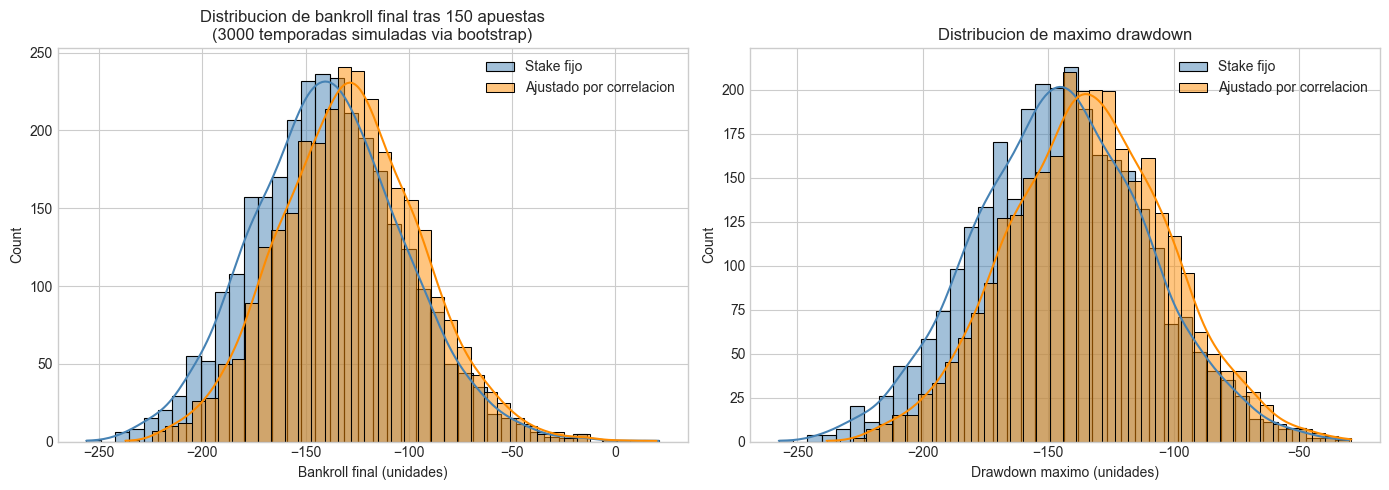

Interpretacion: si el stake ajustado por correlacion reduce el drawdown p5 (peor 5%)
sin reducir demasiado el bankroll final medio, confirma que penalizar por rho real
mejora el perfil de riesgo frente al tope fijo actual de 2 picks / 3u por evento.


In [12]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(final_bankroll_flat, bins=40, color="steelblue", label="Stake fijo", kde=True, ax=axes[0], alpha=0.5)
sns.histplot(final_bankroll_adjusted, bins=40, color="darkorange", label="Ajustado por correlacion", kde=True, ax=axes[0], alpha=0.5)
axes[0].set_title(f"Distribucion de bankroll final tras {BETS_PER_SEASON} apuestas\n({N_SEASONS} temporadas simuladas via bootstrap)")
axes[0].set_xlabel("Bankroll final (unidades)")
axes[0].legend()

sns.histplot(max_drawdown_flat, bins=40, color="steelblue", label="Stake fijo", kde=True, ax=axes[1], alpha=0.5)
sns.histplot(max_drawdown_adjusted, bins=40, color="darkorange", label="Ajustado por correlacion", kde=True, ax=axes[1], alpha=0.5)
axes[1].set_title("Distribucion de maximo drawdown")
axes[1].set_xlabel("Drawdown maximo (unidades)")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Interpretacion: si el stake ajustado por correlacion reduce el drawdown p5 (peor 5%)")
print("sin reducir demasiado el bankroll final medio, confirma que penalizar por rho real")
print("mejora el perfil de riesgo frente al tope fijo actual de 2 picks / 3u por evento.")


### 4bis.5 Conclusiones y siguientes pasos

- **`market_correlation.json`** (exportado en 4bis.2) queda disponible en `data/` para que
  `src/core/pick_rules_engine.py` pueda sustituir `exclusive_groups` (heurística fija) por una
  consulta directa a `rho` real por par de familias, con umbrales (`penalize_above_abs_rho`,
  `block_above_abs_rho`) versionados y medibles en cada corrida de este notebook.
- La cópula gaussiana (4bis.3) cuantifica cuánto se sobreestima la probabilidad de un combo si
  se asume independencia entre familias — útil para corregir el cálculo de EV de combinados
  antes de publicarlos, no solo para bloquear/permitir binariamente.
- El Monte Carlo de portafolio (4bis.4) traduce esa correlación en un efecto medible sobre
  bankroll y drawdown, para decidir si vale la pena mover el límite fijo de riesgo
  (`DEFAULT_MAX_PICKS_PER_EVENT` / `DEFAULT_MAX_STAKE_PER_EVENT`) hacia una regla dependiente
  de `rho`, en vez de un número fijo igual para todos los partidos.
- **Recordatorio de robustez:** vuelve a correr este notebook periódicamente — a medida que
  `sherlock.db` crece, `MIN_CO_OCCURRENCE` deja de ser el cuello de botella y la matriz de
  correlación se vuelve más confiable, especialmente para pares de familias poco frecuentes
  (p. ej. `shotstarget` vs `fouls`).

## 4. Análisis de Rendimiento Global y Filtrado por Estado
Comparación del rendimiento según si el pick es de valor, publicable o bloqueado.

In [7]:
df_eval = df_picks[df_picks['outcome'].notna()].copy()

def summarize_group(df_subset, name="Grupo"):
    total = len(df_subset)
    if total == 0:
        return {'Grupo': name, 'Picks': 0, 'Hits': 0, 'Hit Rate %': 0.0, 'Profit (1u)': 0.0, 'ROI %': 0.0, 'Cuota Media': 0.0}
    hits = df_subset['is_hit'].sum()
    profit = df_subset['profit_1u'].sum()
    roi = (profit / total) * 100.0
    hit_rate = (hits / total) * 100.0
    avg_odds = df_subset['odds'].mean()
    return {
        'Grupo': name,
        'Picks': total,
        'Hits': hits,
        'Hit Rate %': round(hit_rate, 2),
        'Profit (1u)': round(profit, 2),
        'ROI %': round(roi, 2),
        'Cuota Media': round(avg_odds, 2)
    }

summary_rows = [
    summarize_group(df_eval, "1. Todos los Picks Generados"),
    summarize_group(df_eval[df_eval['is_value'] == True], "2. Solo is_value == True"),
    summarize_group(df_eval[df_eval['is_publishable'] == True], "3. Solo is_publishable == True"),
    summarize_group(df_eval[(df_eval['is_publishable'] == True) & (df_eval['is_rule_blocked'] == False)], "4. Publicables SIN Regla Bloqueada"),
    summarize_group(df_eval[df_eval['is_rule_blocked'] == True], "5. Picks Bloqueados por Reglas (Descartados)"),
    summarize_group(df_eval[(df_eval['is_underdog'] == True)], "6. Underdogs"),
]

pd.DataFrame(summary_rows)

,Grupo,Picks,Hits,Hit Rate %,Profit (1u),ROI %,Cuota Media
0,1. Todos los Picks Generados,8118,3271,40.29,-644.72,-7.94,3.13
1,2. Solo is_value == True,580,365,62.93,146.95,25.34,2.02
2,3. Solo is_publishable == True,526,334,63.50,140.39,26.69,2.03
3,4. Publicables SIN Regla Bloqueada,526,334,63.50,140.39,26.69,2.03
4,5. Picks Bloqueados por Reglas (Descartados),1268,568,44.79,-76.04,-6.00,2.26
5,6. Underdogs,224,103,45.98,98.26,43.87,3.24


## 5. Diagnóstico por Familia de Mercado
Identificación de mercados ganadores vs. mercados con pérdidas o errores de estimación.

In [8]:
market_diag = []

# Filtrar evaluables publicables
df_pub_eval = df_eval[df_eval['is_publishable'] == True]

if len(df_pub_eval) == 0:
    print("⚠️ No hay picks con is_publishable == True y resultado liquidado.")
    print("Probando con todos los picks evaluables (is_value o globales)...")
    df_pub_eval = df_eval

for mkt, grp in df_pub_eval.groupby('market_family'):
    res = summarize_group(grp, mkt)
    res['Mercado'] = mkt
    market_diag.append(res)

if len(market_diag) > 0:
    df_mkt = pd.DataFrame(market_diag)
    
    # Detectar el nombre exacto de la columna de profit (con '1u' o 'u')
    profit_col = 'Profit (1u)' if 'Profit (1u)' in df_mkt.columns else ('Profit (u)' if 'Profit (u)' in df_mkt.columns else None)
    
    if profit_col:
        df_mkt = df_mkt.sort_values(by=profit_col, ascending=False)
    
    # Reordenar columnas para visualización clara
    cols_order = ['Mercado', 'Picks', 'Hits', 'Hit Rate %', profit_col or 'Profit', 'ROI %', 'Cuota Media']
    existing_cols = [c for c in cols_order if c in df_mkt.columns]
    df_mkt = df_mkt[existing_cols]
    
    display(df_mkt)
else:
    print("⚠️ No se generaron diagnósticos de mercado porque no hay picks evaluados.")

,Mercado,Picks,Hits,Hit Rate %,Profit (1u),ROI %,Cuota Media
1,cards,278,172,61.87,55.78,20.06,1.98
3,doublechance,138,87,63.04,33.51,24.28,2.01
6,shots,46,27,58.70,19.89,43.24,2.44
7,shotstarget,18,12,66.67,10.30,57.22,2.36
5,result,20,15,75.00,6.53,32.65,1.77
2,corners,9,7,77.78,6.39,71.00,2.13
4,goals,9,8,88.89,4.99,55.44,1.76
0,btts,8,6,75.00,3.00,37.50,1.84


## 6. Curva de Calibración: Probabilidad del Modelo vs. Frecuencia Real
Evaluamos si cuando el modelo dice que un evento tiene 60% de probabilidad, realmente se cumple el 60% de las veces.

Picks con probabilidad disponible: 8118

--- Tabla de Calibración ---


,prob_bin,total_picks,actual_hits,avg_model_prob,actual_hit_rate
0,"(0, 10]",186,38,7.349,20.430
1,"(10, 20]",1014,144,15.455,14.201
2,"(20, 30]",1181,264,25.271,22.354
3,"(30, 40]",1520,437,35.027,28.750
4,"(40, 50]",1564,692,44.906,44.246
5,"(50, 60]",979,534,54.745,54.545
6,"(60, 70]",882,575,64.717,65.193
7,"(70, 80]",642,456,73.647,71.028
8,"(80, 90]",143,124,83.623,86.713
9,"(90, 100]",7,7,92.286,100.000


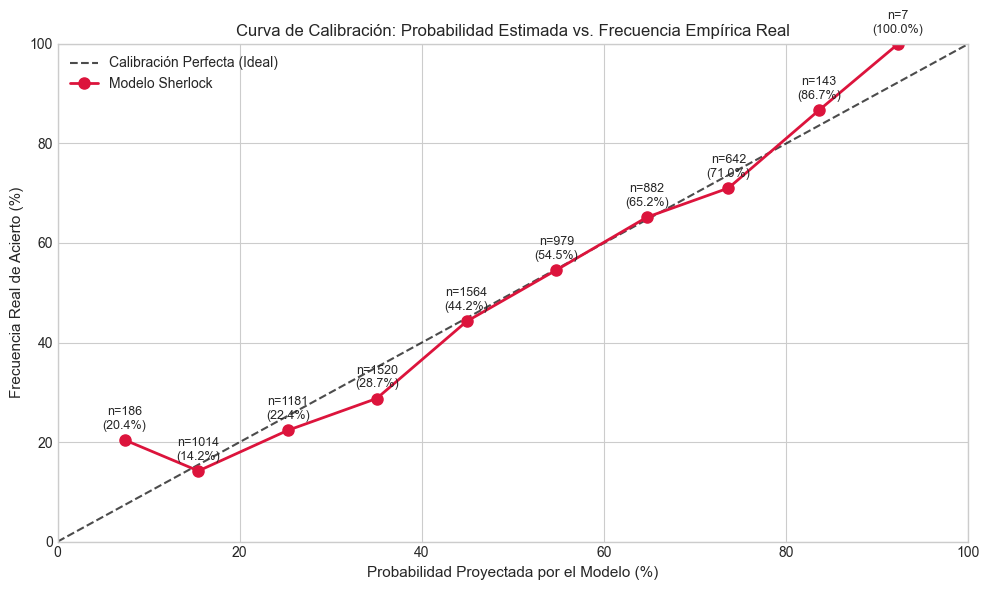

In [9]:
# 1. Extraer probabilidad (preferir model_prob, fallback a calibrated_prob)
df_cal = df_eval.copy()
df_cal['prob_eval'] = df_cal['calibrated_prob'].fillna(df_cal['model_prob'])
df_cal = df_cal[df_cal['prob_eval'].notna()].copy()

print(f"Picks con probabilidad disponible: {len(df_cal)}")

if len(df_cal) > 0:
    # 2. Auto-detectar escala (si el 95% de los datos es <= 1.0, multiplicar por 100)
    if df_cal['prob_eval'].quantile(0.95) <= 1.0:
        print(" Detectada escala 0.0 - 1.0. Convirtiendo a porcentaje (0 - 100%)...")
        df_cal['prob_eval'] = df_cal['prob_eval'] * 100.0

    # 3. Crear intervalos de 10%
    bins = np.arange(0, 105, 10)
    df_cal['prob_bin'] = pd.cut(df_cal['prob_eval'], bins=bins)

    cal_summary = df_cal.groupby('prob_bin', observed=False).agg(
        total_picks=('is_hit', 'count'),
        actual_hits=('is_hit', 'sum'),
        avg_model_prob=('prob_eval', 'mean')
    ).reset_index()

    cal_summary['actual_hit_rate'] = np.where(
        cal_summary['total_picks'] > 0,
        (cal_summary['actual_hits'] / cal_summary['total_picks']) * 100.0,
        np.nan
    )

    # Imprimir tabla para verificar qué datos hay en cada intervalo
    print("\n--- Tabla de Calibración ---")
    display(cal_summary.dropna(subset=['avg_model_prob']))

    # 4. Graficar (usamos total_picks >= 1 para que pinte todos los puntos disponibles)
    valid_bins = cal_summary[cal_summary['total_picks'] >= 1].dropna(subset=['avg_model_prob', 'actual_hit_rate'])

    plt.figure(figsize=(10, 6))
    plt.plot([0, 100], [0, 100], 'k--', label='Calibración Perfecta (Ideal)', alpha=0.7)
    
    if len(valid_bins) > 0:
        plt.plot(valid_bins['avg_model_prob'], valid_bins['actual_hit_rate'], 
                 marker='o', markersize=8, color='crimson', linewidth=2, label='Modelo Sherlock')

        for _, r in valid_bins.iterrows():
            plt.annotate(f"n={int(r['total_picks'])}\n({r['actual_hit_rate']:.1f}%)", 
                         (r['avg_model_prob'], r['actual_hit_rate']),
                         textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9)
    else:
        plt.text(50, 50, "Sin suficientes datos con probabilidad válida", ha='center', fontsize=12, color='red')

    plt.title("Curva de Calibración: Probabilidad Estimada vs. Frecuencia Empírica Real", fontsize=12)
    plt.xlabel("Probabilidad Proyectada por el Modelo (%)", fontsize=11)
    plt.ylabel("Frecuencia Real de Acierto (%)", fontsize=11)
    plt.legend()
    plt.xlim(0, 100)
    plt.ylim(0, 100)
    plt.tight_layout()
    plt.show()
else:
    print("⚠️ No hay picks con 'model_prob' ni 'calibrated_prob' válidos en df_eval.")

## 7. Detección de Errores por Rango de Cuotas (Odds Slippage / Outliers)
Revisión del rendimiento según el rango de cuota ofrecida por las casas de apuestas.

In [10]:
df_eval['odds_bracket'] = pd.cut(df_eval['odds'], bins=[1.0, 1.4, 1.7, 2.0, 2.5, 3.5, 5.0, 20.0])

odds_summary = df_eval[df_eval['is_publishable'] == True].groupby('odds_bracket', observed=False).agg(
    total_picks=('is_hit', 'count'),
    hits=('is_hit', 'sum'),
    profit=('profit_1u', 'sum'),
    mean_odds=('odds', 'mean')
).reset_index()

odds_summary['hit_rate_%'] = (odds_summary['hits'] / odds_summary['total_picks']) * 100.0
odds_summary['roi_%'] = (odds_summary['profit'] / odds_summary['total_picks']) * 100.0
odds_summary

,odds_bracket,total_picks,hits,profit,mean_odds,hit_rate_%,roi_%
0,"(1.0, 1.4]",4,2,-1.20,1.400,50.000,-30.000
1,"(1.4, 1.7]",66,54,21.28,1.616,81.818,32.242
2,"(1.7, 2.0]",206,132,38.11,1.854,64.078,18.500
3,"(2.0, 2.5]",250,146,82.20,2.286,58.400,32.880
4,"(2.5, 3.5]",0,0,0.00,NaN,NaN,NaN
5,"(3.5, 5.0]",0,0,0.00,NaN,NaN,NaN
6,"(5.0, 20.0]",0,0,0.00,NaN,NaN,NaN


## 8. Curva de Equity Acumulada
Evolución del bankroll apostando 1 unidad plana en picks publicables a lo largo del tiempo.

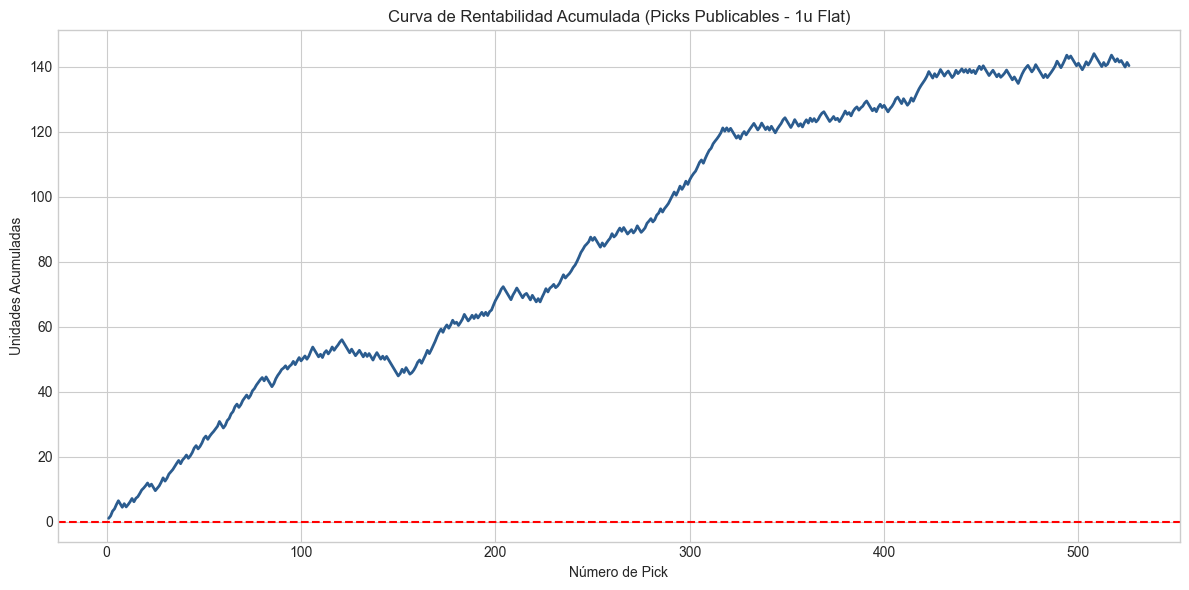

In [11]:
df_equity = df_eval[df_eval['is_publishable'] == True].sort_values(by='match_date').copy()
df_equity['cumulative_profit'] = df_equity['profit_1u'].cumsum()
df_equity['pick_num'] = np.arange(1, len(df_equity) + 1)

plt.figure(figsize=(12, 6))
plt.plot(df_equity['pick_num'], df_equity['cumulative_profit'], color='#2b5c8f', linewidth=2)
plt.axhline(0, color='red', linestyle='--')
plt.title("Curva de Rentabilidad Acumulada (Picks Publicables - 1u Flat)")
plt.xlabel("Número de Pick")
plt.ylabel("Unidades Acumuladas")
plt.tight_layout()
plt.show()

## 9. Exportación del Reporte Completo a Excel
Genera un archivo Excel detallado con todas las hojas de diagnóstico para análisis offline.

In [18]:
output_filename = f'Auditoria_Sherlock_{datetime.now().strftime("%Y%m%d_%H%M")}.xlsx'
with pd.ExcelWriter(output_filename, engine='openpyxl') as writer:
    pd.DataFrame(summary_rows).to_excel(writer, sheet_name='Resumen General', index=False)
    df_mkt.to_excel(writer, sheet_name='Por Mercado', index=False)
    odds_summary.to_excel(writer, sheet_name='Por Rango Cuotas', index=False)
    df_eval.to_excel(writer, sheet_name='Detalle Todos Picks', index=False)

print(f"📁 Reporte completo generado con éxito: {output_filename}")

📁 Reporte completo generado con éxito: Auditoria_Sherlock_20260823_1933.xlsx
